# 01 — Exploratory Data Analysis with PySpark
**Project:** Predicting Airbnb Listing Prices and Analyzing Key Drivers of Pricing Using Distributed Data Processing (PySpark)
**Course:** BAN5600

This notebook loads the Inside Airbnb New York City `listings.csv` snapshot (scraped 14–15 September 2026)
into Spark, cleans the fields we need, and produces the descriptive statistics and figures for the
Project Introduction. All heavy work (parsing, filtering, aggregation, correlation) runs in Spark;
only small aggregated results are brought back to the driver for plotting.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.sql import SparkSession, Window, functions as F, types as T

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
DATA_PATH = PROJECT_DIR / "listings.csv"
FIG_DIR = PROJECT_DIR / "figures"
OUT_DIR = PROJECT_DIR / "outputs"
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

spark = (
    SparkSession.builder.master("local[*]")
    .appName("Airbnb-NYC-EDA")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/20 13:44:08 WARN Utils: Your hostname, localhost, resolves to a loopback address: 127.0.0.1; using <local-ip> instead (on interface en0)
26/10/20 13:44:08 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/20 13:44:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


In [2]:
# Plot style shared by every figure (colorblind-checked categorical palette, hairline grid)
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a9a", "#c62f2f"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 2. Load the raw data
The file has free-text fields (`description`, `amenities`) that contain commas, quotes and line breaks,
so we read it with `multiLine=True` and `escape='"'`. Every column is read as a string first and cast
explicitly in the cleaning step, which keeps the types under our control.

In [3]:
raw = (
    spark.read.option("header", True)
    .option("multiLine", True)
    .option("escape", '"')
    .csv(str(DATA_PATH))
)
n_rows, n_cols = raw.count(), len(raw.columns)
print(f"Raw data: {n_rows:,} listings x {n_cols} columns")
raw.select("id", "last_scraped", "neighbourhood_group_cleansed", "room_type", "price", "minimum_nights").show(5, truncate=False)

Raw data: 29,918 listings x 90 columns
+-------------------+------------+----------------------------+---------------+-------+--------------+
|id                 |last_scraped|neighbourhood_group_cleansed|room_type      |price  |minimum_nights|
+-------------------+------------+----------------------------+---------------+-------+--------------+
|1352055619826961511|2026-09-14  |Brooklyn                    |Entire home/apt|NULL   |30            |
|1215930899551057941|2026-09-14  |Queens                      |Private room   |$164.55|31            |
|1203866180302079266|2026-09-15  |Brooklyn                    |Private room   |NULL   |30            |
|15310580           |2026-09-15  |Manhattan                   |Entire home/apt|NULL   |30            |
|32842295           |2026-09-15  |Brooklyn                    |Private room   |NULL   |80            |
+-------------------+------------+----------------------------+---------------+-------+--------------+
only showing top 5 rows


### 2.1 Missing values in the raw file

In [4]:
missing = (
    raw.select([F.avg(F.col(c).isNull().cast("double")).alias(c) for c in raw.columns])
    .toPandas().T.rename(columns={0: "share_missing"})
    .sort_values("share_missing", ascending=False)
)
missing.to_csv(OUT_DIR / "missing_values.csv")
fully_empty = missing.index[missing.share_missing == 1].tolist()
print(f"{len(fully_empty)} columns are 100% empty in this snapshot:", fully_empty)
missing[(missing.share_missing > 0) & (missing.share_missing < 1)].head(15).style.format("{:.1%}")

12 columns are 100% empty in this snapshot: ['host_response_rate', 'host_total_listings_count', 'host_thumbnail_url', 'neighbourhood', 'host_since', 'host_neighbourhood', 'host_response_time', 'host_acceptance_rate', 'instant_bookable', 'bathrooms', 'neighborhood_overview', 'calendar_updated']


,share_missing
license,82.9%
source,70.2%
host_about,40.1%
price_quote_total_price,35.1%
price_quote_price_per_night,35.1%
price,35.1%
estimated_revenue_l365d,35.1%
review_scores_value,27.2%
review_scores_location,27.2%
review_scores_checkin,27.1%


## 3. Cleaning and feature preparation
* `price`: strip `$` and `,`, cast to double. About one-third of listings have no price (not bookable on the scrape date).
* `bathrooms` is empty in this snapshot, so we parse the number from `bathrooms_text` ("1.5 shared baths", "Half-bath") and keep a `shared_bath` flag.
* `amenities` is a JSON array; we count its items.
* `t`/`f` flags become 1/0.
* `stay_type`: since NYC Local Law 18 (enforced September 2023), stays under 30 nights require host registration.
  We flag listings whose minimum stay is 30+ nights; their nightly price is derived from a monthly quote.
* `license_status`: registered (`OSE-STRREG-…`), exempt, or not reported.

In [5]:
NUMERIC_COLS = [
    "accommodates", "bedrooms", "beds", "minimum_nights", "maximum_nights",
    "availability_30", "availability_60", "availability_90", "availability_365",
    "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
    "review_scores_checkin", "review_scores_communication", "review_scores_location", "review_scores_value",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
    "calculated_host_listings_count", "hosts_time_as_host_years", "latitude", "longitude",
]

def to_flag(col):
    return F.when(F.col(col) == "t", 1).when(F.col(col) == "f", 0).cast("int")

bath_text = F.lower(F.col("bathrooms_text"))
license_up = F.upper(F.col("license"))

df = raw.select(
    "id", "host_id", "neighbourhood_cleansed", "neighbourhood_group_cleansed", "room_type", "property_type",
    "bathrooms_text", "amenities", "license", "host_is_superhost", "host_identity_verified", "price",
    *NUMERIC_COLS,
)
for c in NUMERIC_COLS:
    df = df.withColumn(c, F.col(c).cast("double"))

df = (
    df.withColumnRenamed("neighbourhood_cleansed", "neighbourhood")
    .withColumnRenamed("neighbourhood_group_cleansed", "borough")
    .withColumn("price", F.regexp_replace("price", r"[$,]", "").cast("double"))
    .withColumn("bathrooms", F.when(bath_text.contains("half"), 0.5)
                .otherwise(F.regexp_extract(bath_text, r"(\d+(\.\d+)?)", 1).cast("double")))
    .withColumn("shared_bath", bath_text.contains("shared").cast("int"))
    .withColumn("amenities_count", F.size(F.from_json("amenities", T.ArrayType(T.StringType()))))
    .withColumn("is_superhost", to_flag("host_is_superhost"))
    .withColumn("identity_verified", to_flag("host_identity_verified"))
    .withColumn("stay_type", F.when(F.col("minimum_nights") >= 30, "30+ nights").otherwise("Under 30 nights"))
    .withColumn("license_status",
                F.when(license_up.startswith("OSE-STRREG"), "Registered")
                .when(license_up == "EXEMPT", "Exempt").otherwise("Not reported"))
    .drop("bathrooms_text", "amenities", "license", "host_is_superhost", "host_identity_verified")
    .cache()
)
df.select("price", "bathrooms", "shared_bath", "amenities_count", "is_superhost", "stay_type", "license_status").show(5)

+------+---------+-----------+---------------+------------+----------+--------------+
| price|bathrooms|shared_bath|amenities_count|is_superhost| stay_type|license_status|
+------+---------+-----------+---------------+------------+----------+--------------+
|  NULL|      1.5|          0|              5|           0|30+ nights|  Not reported|
|164.55|      1.0|          0|             11|           0|30+ nights|  Not reported|
|  NULL|      1.5|          0|             10|           0|30+ nights|  Not reported|
|  NULL|      1.0|          0|              5|           0|30+ nights|  Not reported|
|  NULL|      1.0|          0|             13|           0|30+ nights|  Not reported|
+------+---------+-----------+---------------+------------+----------+--------------+
only showing top 5 rows


### 3.1 Analytic sample for price
We keep listings with a price and trim the extreme 1% at each tail (very likely data-entry errors or
luxury outliers that would dominate a squared-error loss). The model target is `log_price`, because
price is strongly right-skewed.

In [6]:
priced = df.filter(F.col("price").isNotNull())
p01, p99 = priced.approxQuantile("price", [0.01, 0.99], 0.0001)
clean = (
    priced.filter((F.col("price") >= p01) & (F.col("price") <= p99))
    .withColumn("log_price", F.log("price"))
    .cache()
)
n_priced, n_clean = priced.count(), clean.count()
print(f"Listings with a price: {n_priced:,} ({n_priced / n_rows:.1%} of all listings)")
print(f"Trim bounds: ${p01:,.2f} - ${p99:,.2f}  ->  analytic sample: {n_clean:,} listings")

sample_summary = pd.DataFrame({
    "step": ["Raw listings", "With a listed price", "After 1%/99% trim (analytic sample)"],
    "listings": [n_rows, n_priced, n_clean],
})
sample_summary.to_csv(OUT_DIR / "sample_flow.csv", index=False)
sample_summary

Listings with a price: 19,406 (64.9% of all listings)
Trim bounds: $43.27 - $1,997.43  ->  analytic sample: 19,018 listings


,step,listings
0,Raw listings,29918
1,With a listed price,19406
2,After 1%/99% trim (analytic sample),19018


## 4. Descriptive statistics

In [7]:
DESC_COLS = [
    "price", "log_price", "accommodates", "bedrooms", "beds", "bathrooms", "amenities_count",
    "minimum_nights", "availability_365", "number_of_reviews", "number_of_reviews_ltm",
    "review_scores_rating", "estimated_occupancy_l365d", "calculated_host_listings_count",
    "hosts_time_as_host_years",
]
desc = (
    clean.select(DESC_COLS)
    .summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
    .toPandas().set_index("summary").T.astype(float)
)
desc.columns = ["N", "Mean", "SD", "Min", "Q1", "Median", "Q3", "Max"]
desc.to_csv(OUT_DIR / "descriptive_numeric.csv")
desc.round(2)

,N,Mean,SD,Min,Q1,Median,Q3,Max
price,19018.0,273.22,266.37,43.27,105.46,182.34,331.85,1997.43
log_price,19018.0,5.26,0.81,3.77,4.66,5.21,5.80,7.60
accommodates,19018.0,2.91,1.99,1.00,2.00,2.00,4.00,16.00
bedrooms,18990.0,1.28,0.86,0.00,1.00,1.00,2.00,9.00
beds,18132.0,1.70,1.16,1.00,1.00,1.00,2.00,20.00
bathrooms,18942.0,1.17,0.49,0.00,1.00,1.00,1.00,10.50
amenities_count,19018.0,31.02,14.69,0.00,21.00,30.00,42.00,110.00
minimum_nights,19011.0,23.72,18.95,1.00,4.00,30.00,30.00,365.00
availability_365,19018.0,253.72,102.23,0.00,179.00,276.00,344.00,365.00
number_of_reviews,19018.0,42.34,97.80,0.00,0.00,7.00,45.00,4894.00


In [8]:
raw_price = priced.select("price").summary("mean", "stddev", "50%", "max").toPandas()
skew = priced.select(F.skewness("price")).first()[0]
print("Raw price (before trim):", dict(zip(raw_price.summary, raw_price.price)), f"skewness={skew:.2f}")
print("log_price skewness (analytic sample):", round(clean.select(F.skewness("log_price")).first()[0], 2))

Raw price (before trim): {'mean': '310.165606513451', 'stddev': '574.094114551624', '50%': '182.42', 'max': '31537.82'} skewness=17.56
log_price skewness (analytic sample): 0.34


In [9]:
def price_profile(group_col, data=clean):
    """Listing count, share and price summary for one categorical variable, computed in Spark."""
    total = data.count()
    out = (
        data.groupBy(group_col)
        .agg(
            F.count("*").alias("listings"),
            F.round(F.mean("price"), 2).alias("mean_price"),
            F.round(F.percentile_approx("price", 0.5, 10000), 2).alias("median_price"),
            F.round(F.mean("availability_365"), 1).alias("mean_availability_365"),
            F.round(F.mean("number_of_reviews_ltm"), 2).alias("mean_reviews_ltm"),
        )
        .withColumn("share", F.round(F.col("listings") / total * 100, 1))
        .orderBy(F.desc("listings"))
        .toPandas()
    )
    out.to_csv(OUT_DIR / f"price_by_{group_col}.csv", index=False)
    return out

price_profile("room_type")

,room_type,listings,mean_price,median_price,mean_availability_365,mean_reviews_ltm,share
0,Entire home/apt,10007,302.05,215.90,253.4,4.73,52.6
1,Private room,8499,220.33,117.00,251.8,10.62,44.7
2,Hotel room,393,709.93,594.00,298.0,1.71,2.1
3,Shared room,119,184.57,117.83,274.4,7.19,0.6


In [10]:
price_profile("borough")

,borough,listings,mean_price,median_price,mean_availability_365,mean_reviews_ltm,share
0,Manhattan,8565,374.57,259.18,254.0,7.74,45.0
1,Brooklyn,6279,208.82,157.45,247.3,7.15,33.0
2,Queens,3166,169.17,127.28,258.5,7.31,16.6
3,Bronx,730,138.94,110.77,275.3,5.02,3.8
4,Staten Island,278,143.09,107.53,279.6,4.19,1.5


In [11]:
price_profile("stay_type")

,stay_type,listings,mean_price,median_price,mean_availability_365,mean_reviews_ltm,share
0,30+ nights,13973,205.53,147.84,261.5,0.83,73.5
1,Under 30 nights,5045,460.70,369.74,232.1,25.29,26.5


In [12]:
price_profile("license_status")

,license_status,listings,mean_price,median_price,mean_availability_365,mean_reviews_ltm,share
0,Not reported,14540,221.36,153.97,262.5,1.87,76.5
1,Exempt,2375,590.96,504.78,227.3,22.71,12.5
2,Registered,2103,272.96,226.00,222.7,27.57,11.1


In [13]:
# Local Law 18 bars entire-home rentals under 30 nights: who is still offering them?
(clean.filter((F.col("stay_type") == "Under 30 nights") & (F.col("room_type") == "Entire home/apt"))
 .groupBy("license_status").count()
 .withColumn("share", F.round(F.col("count") / F.sum("count").over(Window.partitionBy()) * 100, 1))
 .show())

+--------------+-----+-----+
|license_status|count|share|
+--------------+-----+-----+
|  Not reported|    9|  0.6|
|    Registered|  343| 24.4|
|        Exempt| 1056| 75.0|
+--------------+-----+-----+



In [14]:
superhost = price_profile("is_superhost")
superhost

,is_superhost,listings,mean_price,median_price,mean_availability_365,mean_reviews_ltm,share
0,0,13660,278.53,184.85,261.6,4.60,71.8
1,1,5358,259.70,176.50,233.6,14.23,28.2


### 4.1 Neighborhood demand (preview of research question 3)
Demand is proxied by **few open nights** (`availability_365`) combined with **many recent reviews**
(`number_of_reviews_ltm`, a stand-in for completed stays). This uses all listings, priced or not.
Reviews are averaged on the log scale, `ln(1 + reviews)`, so one high-volume operator cannot dominate a
neighborhood. The demand index is the average of the two z-scores (availability reversed), over
neighborhoods with at least 50 listings. `top_host_share` flags neighborhoods dominated by one host.

In [15]:
top_host = (
    df.groupBy("neighbourhood", "host_id").count()
    .groupBy("neighbourhood").agg(F.max("count").alias("top_host_listings"))
)
hood = (
    df.groupBy("borough", "neighbourhood")
    .agg(
        F.count("*").alias("listings"),
        F.mean("availability_365").alias("mean_availability_365"),
        F.mean(F.log1p("number_of_reviews_ltm")).alias("mean_log_reviews_ltm"),
        F.mean("number_of_reviews_ltm").alias("mean_reviews_ltm"),
        F.mean("estimated_occupancy_l365d").alias("mean_est_occupancy_nights"),
        F.percentile_approx("price", 0.5, 10000).alias("median_price"),
    )
    .filter(F.col("listings") >= 50)
    .join(top_host, "neighbourhood")
    .withColumn("top_host_share", F.col("top_host_listings") / F.col("listings"))
)
stats = hood.agg(*[F.mean(c).alias(f"{c}_m") for c in ["mean_availability_365", "mean_log_reviews_ltm"]],
                 *[F.stddev(c).alias(f"{c}_s") for c in ["mean_availability_365", "mean_log_reviews_ltm"]]).first()
hood = hood.withColumn(
    "demand_index",
    ((F.col("mean_log_reviews_ltm") - stats.mean_log_reviews_ltm_m) / stats.mean_log_reviews_ltm_s
     - (F.col("mean_availability_365") - stats.mean_availability_365_m) / stats.mean_availability_365_s) / 2,
)
hood_pd = hood.orderBy(F.desc("demand_index")).toPandas()
hood_pd.to_csv(OUT_DIR / "neighbourhood_demand.csv", index=False)
print(f"{len(hood_pd)} neighborhoods with >= 50 listings")
hood_pd.head(10).round(2)

85 neighborhoods with >= 50 listings


,neighbourhood,borough,listings,mean_availability_365,mean_log_reviews_ltm,mean_reviews_ltm,mean_est_occupancy_nights,median_price,top_host_listings,top_host_share,demand_index
0,Fort Hamilton,Brooklyn,98,256.01,2.63,32.27,171.37,212.00,63,0.64,2.56
1,Gowanus,Brooklyn,111,171.09,0.96,7.11,86.91,224.75,9,0.08,0.68
2,Downtown Brooklyn,Brooklyn,65,190.28,1.05,19.60,67.14,252.00,9,0.14,0.64
3,Prospect Heights,Brooklyn,143,111.79,0.53,4.34,45.42,228.36,2,0.01,0.60
4,Park Slope,Brooklyn,230,137.78,0.69,5.10,62.67,207.74,6,0.03,0.59
5,Chinatown,Manhattan,248,174.28,0.92,8.56,68.77,296.00,22,0.09,0.58
6,Boerum Hill,Brooklyn,105,150.98,0.76,9.24,60.73,283.33,7,0.07,0.57
7,Gramercy,Manhattan,189,171.22,0.87,5.90,76.10,220.52,20,0.11,0.54
8,Elmhurst,Queens,266,105.67,0.46,2.19,45.16,72.68,48,0.18,0.53
9,South Ozone Park,Queens,70,243.66,1.31,17.60,85.76,181.33,6,0.09,0.51


## 5. Correlation with log price

In [16]:
CORR_COLS = [
    "log_price", "accommodates", "bedrooms", "beds", "bathrooms", "amenities_count", "minimum_nights",
    "availability_365", "number_of_reviews", "number_of_reviews_ltm", "review_scores_rating",
    "calculated_host_listings_count", "hosts_time_as_host_years", "is_superhost",
]
corr_df = clean.select(CORR_COLS).na.drop()
vec = VectorAssembler(inputCols=CORR_COLS, outputCol="v").transform(corr_df).select("v")
corr = pd.DataFrame(Correlation.corr(vec, "v", "pearson").first()[0].toArray(), index=CORR_COLS, columns=CORR_COLS)
corr.to_csv(OUT_DIR / "correlation_matrix.csv")
print(f"Complete cases used: {corr_df.count():,}")
corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False).round(3)

Complete cases used: 13,563


accommodates                      0.466
beds                              0.370
minimum_nights                   -0.367
bedrooms                          0.283
number_of_reviews_ltm             0.210
bathrooms                         0.198
amenities_count                   0.180
hosts_time_as_host_years         -0.157
number_of_reviews                 0.095
calculated_host_listings_count   -0.078
availability_365                  0.041
review_scores_rating              0.041
is_superhost                      0.010
Name: log_price, dtype: float64

### 5.1 Distance to Midtown
A simple spatial feature: approximate distance (km) from Times Square (40.758, -73.9855), using an
equirectangular projection, which is accurate enough at city scale.

In [17]:
clean = clean.withColumn(
    "km_to_midtown",
    F.sqrt(((F.col("longitude") + 73.9855) * F.cos(F.radians(F.lit(40.758)))) ** 2 + (F.col("latitude") - 40.758) ** 2) * 111.0,
)
print("corr(km_to_midtown, log_price) =", round(clean.stat.corr("km_to_midtown", "log_price"), 3))
(clean.groupBy("borough", "neighbourhood")
 .agg(F.count("*").alias("listings"), F.percentile_approx("price", 0.5, 10000).alias("median_price"))
 .filter("listings >= 50").orderBy(F.desc("median_price")).show(10))

corr(km_to_midtown, log_price) = -0.41
+---------+------------------+--------+------------+
|  borough|     neighbourhood|listings|median_price|
+---------+------------------+--------+------------+
|Manhattan|           Tribeca|      66|       578.3|
|Manhattan|Financial District|     313|      567.76|
|Manhattan|              SoHo|     140|       565.0|
|Manhattan|  Theater District|     269|      533.34|
|Manhattan|           Midtown|    1385|      463.02|
|Manhattan| Greenwich Village|      78|       449.0|
|Manhattan|      West Village|     162|      302.67|
|Manhattan|         Chinatown|     162|       296.0|
|Manhattan|   Lower East Side|     325|       289.0|
| Brooklyn|       Boerum Hill|      66|      283.33|
+---------+------------------+--------+------------+
only showing top 10 rows


## 6. Visualizations

**Figure 1 — Distribution of nightly price.** Histogram bins are counted in Spark.

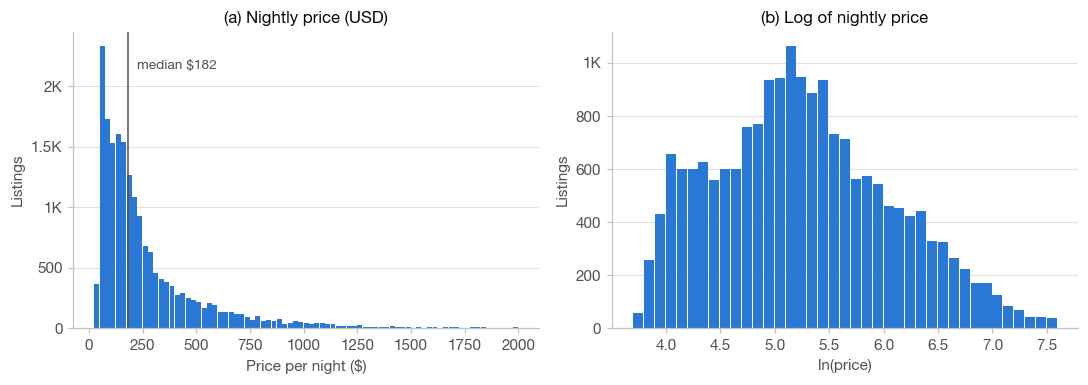

In [18]:
def spark_hist(data, col, width, lo):
    """Return bin left edges and counts, binning in Spark."""
    h = (data.select(F.floor((F.col(col) - lo) / width).alias("b")).groupBy("b").count().orderBy("b").toPandas())
    return lo + h.b.values * width, h["count"].values

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
edges, counts = spark_hist(clean, "price", 25, 0)
axes[0].bar(edges, counts, width=25 * 0.92, align="edge", color=SERIES[0])
med = clean.approxQuantile("price", [0.5], 0.0001)[0]
axes[0].axvline(med, color=INK2, lw=1)
axes[0].annotate(f"median ${med:,.0f}", (med, counts.max() * 0.92), xytext=(6, 0), textcoords="offset points", color=INK2, fontsize=9)
axes[0].set(title="(a) Nightly price (USD)", xlabel="Price per night ($)", ylabel="Listings")

edges, counts = spark_hist(clean, "log_price", 0.1, 3.5)
axes[1].bar(edges, counts, width=0.1 * 0.92, align="edge", color=SERIES[0])
axes[1].set(title="(b) Log of nightly price", xlabel="ln(price)", ylabel="Listings")
for ax in axes:
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:g}K" if v >= 1000 else f"{v:.0f}"))
fig.tight_layout()
save(fig, "fig1_price_distribution")

**Figure 2 — Price by room type.** Box statistics (quartiles, 5th/95th percentile whiskers) come from `percentile_approx` in Spark.

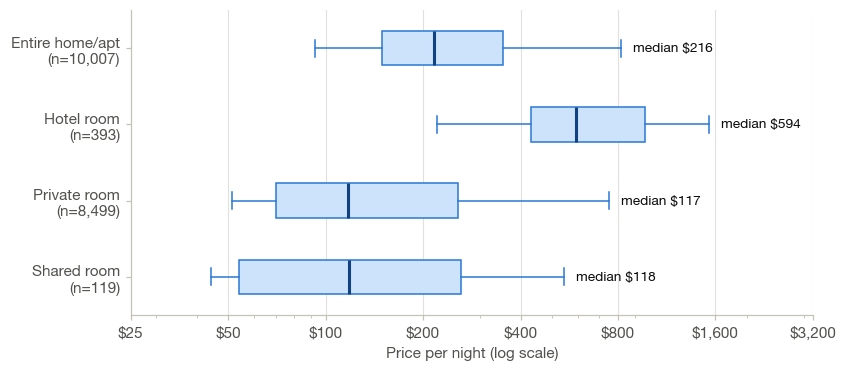

In [19]:
q = (
    clean.groupBy("room_type")
    .agg(F.percentile_approx("price", [0.05, 0.25, 0.5, 0.75, 0.95], 10000).alias("q"), F.count("*").alias("n"))
    .toPandas().set_index("room_type")
    .loc[["Entire home/apt", "Hotel room", "Private room", "Shared room"]]
)
boxes = [dict(label=f"{rt}\n(n={r.n:,})", whislo=r.q[0], q1=r.q[1], med=r.q[2], q3=r.q[3], whishi=r.q[4], fliers=[])
         for rt, r in q.iterrows()]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bxp(boxes, vert=False, showfliers=False, widths=0.45, patch_artist=True,
       boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0], linewidth=1),
       medianprops=dict(color="#104281", linewidth=2), whiskerprops=dict(color=SERIES[0]), capprops=dict(color=SERIES[0]))
for i, (_, r) in enumerate(q.iterrows(), start=1):
    ax.annotate(f"median ${r.q[2]:,.0f}", (r.q[4], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_xscale("log")
ax.set_xticks([25, 50, 100, 200, 400, 800, 1600, 3200])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(xlabel="Price per night (log scale)")
save(fig, "fig2_price_by_room_type")

**Figure 3 — Median price by borough and room type.**

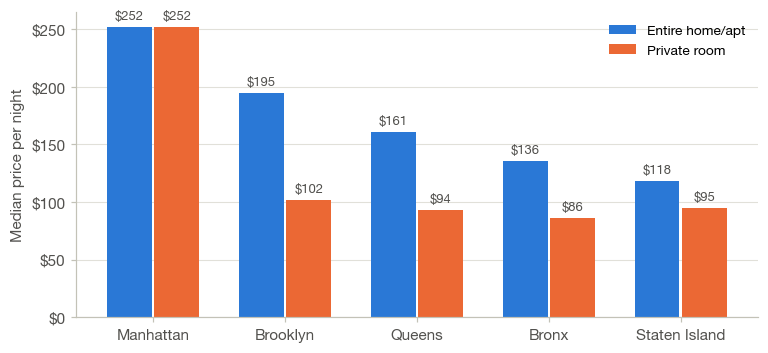

In [20]:
br = (
    clean.filter(F.col("room_type").isin("Entire home/apt", "Private room"))
    .groupBy("borough", "room_type").agg(F.percentile_approx("price", 0.5, 10000).alias("median_price"))
    .toPandas().pivot(index="borough", columns="room_type", values="median_price")
    .loc[["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]]
)
x = np.arange(len(br))
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, rt in enumerate(["Entire home/apt", "Private room"]):
    bars = ax.bar(x + (i - 0.5) * 0.36, br[rt], width=0.34, color=SERIES[i], label=rt)
    ax.bar_label(bars, labels=[f"${v:,.0f}" for v in br[rt]], padding=3, fontsize=8.5, color=INK2)
ax.set_xticks(x, br.index)
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set(ylabel="Median price per night")
ax.legend(loc="upper right")
save(fig, "fig3_price_by_borough_room")

**Figure 4 — Where prices are high.** Only three columns (lat, lon, log price) are collected for the map.

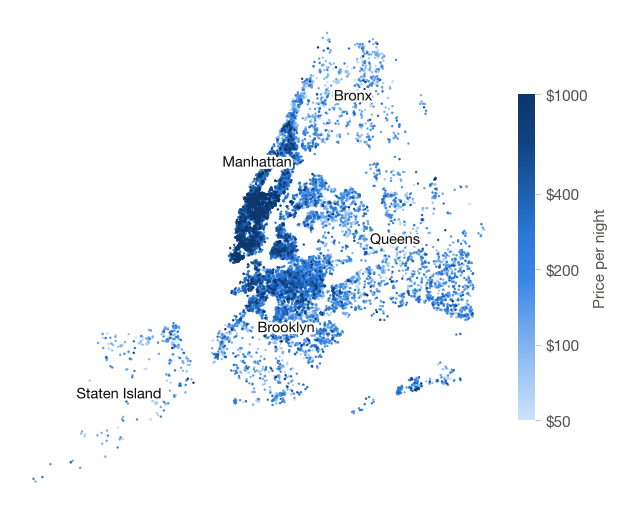

In [21]:
geo = clean.select("longitude", "latitude", "log_price").orderBy("log_price").toPandas()
fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(geo.longitude, geo.latitude, c=geo.log_price, s=2.5, linewidths=0,
                cmap=LinearSegmentedColormap.from_list("blue", BLUE_RAMP), vmin=np.log(50), vmax=np.log(1000))
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks([]); ax.set_yticks([])
for name, lon, lat in [("Manhattan", -73.985, 40.79), ("Brooklyn", -73.95, 40.64), ("Queens", -73.82, 40.72),
                       ("Bronx", -73.87, 40.85), ("Staten Island", -74.15, 40.58)]:
    ax.annotate(name, (lon, lat), fontsize=9.5, color=INK, weight="semibold", ha="center",
                path_effects=[pe.withStroke(linewidth=3, foreground="white")])
cb = fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.02)
ticks = [50, 100, 200, 400, 1000]
cb.set_ticks(np.log(ticks), labels=[f"${t}" for t in ticks])
cb.outline.set_visible(False)
cb.set_label("Price per night", color=INK2)
save(fig, "fig4_price_map")

**Figure 5 — Minimum stay after Local Law 18.** Two measures, so two panels (no dual axis).

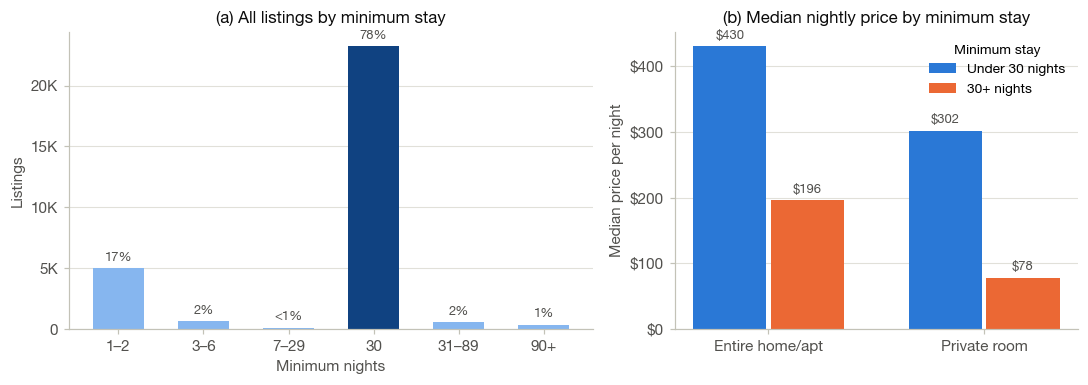

In [22]:
bucket = (F.when(F.col("minimum_nights") <= 2, "1–2").when(F.col("minimum_nights") <= 6, "3–6")
          .when(F.col("minimum_nights") <= 29, "7–29").when(F.col("minimum_nights") == 30, "30")
          .when(F.col("minimum_nights") <= 89, "31–89").otherwise("90+"))
order = ["1–2", "3–6", "7–29", "30", "31–89", "90+"]
mn = df.filter(F.col("minimum_nights").isNotNull()).groupBy(bucket.alias("b")).count().toPandas().set_index("b").loc[order]
st = (clean.filter(F.col("room_type").isin("Entire home/apt", "Private room"))
      .groupBy("stay_type", "room_type").agg(F.percentile_approx("price", 0.5, 10000).alias("median_price"))
      .toPandas().pivot(index="room_type", columns="stay_type", values="median_price"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
cols = ["#104281" if b == "30" else "#86b6ef" for b in order]
bars = axes[0].bar(order, mn["count"], width=0.6, color=cols)
axes[0].bar_label(bars, labels=[f"{c / mn['count'].sum():.0%}" if c / mn['count'].sum() >= 0.005 else "<1%" for c in mn["count"]], padding=3, fontsize=8.5, color=INK2)
axes[0].set(title="(a) All listings by minimum stay", xlabel="Minimum nights", ylabel="Listings")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}K" if v >= 1000 else f"{v:.0f}"))

x = np.arange(2)
for i, s in enumerate(["Under 30 nights", "30+ nights"]):
    b = axes[1].bar(x + (i - 0.5) * 0.36, st.loc[["Entire home/apt", "Private room"], s], width=0.34, color=SERIES[i], label=s)
    axes[1].bar_label(b, labels=[f"${v:,.0f}" for v in b.datavalues], padding=3, fontsize=8.5, color=INK2)
axes[1].set_xticks(x, ["Entire home/apt", "Private room"])
axes[1].set(title="(b) Median nightly price by minimum stay", ylabel="Median price per night")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
axes[1].legend(title="Minimum stay", title_fontsize=9)
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig5_minimum_stay")

**Figure 6 — Correlation matrix** (Pearson, complete cases). Shows which numeric features move with log price and where features overlap (multicollinearity).

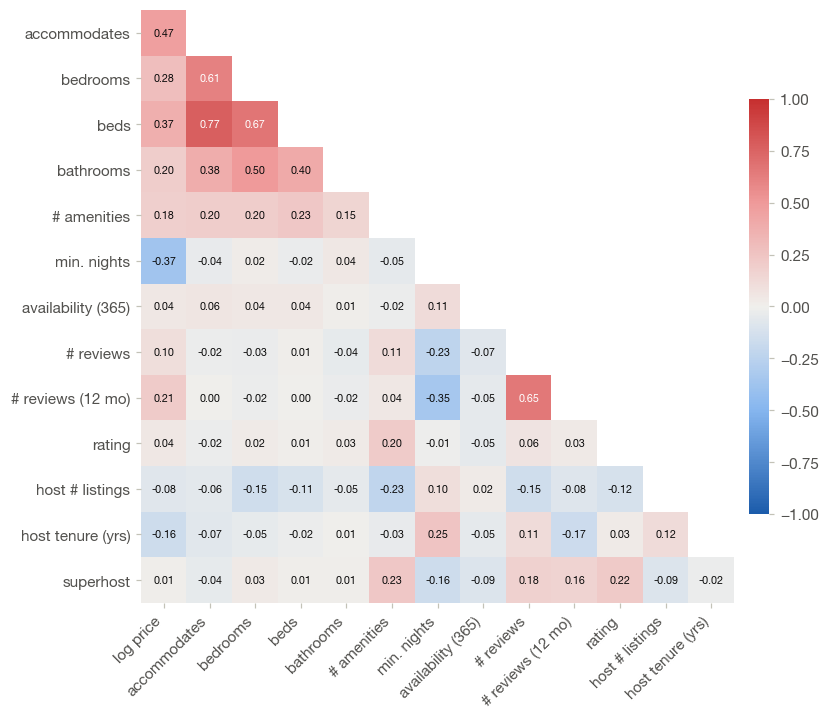

In [23]:
labels = {"log_price": "log price", "accommodates": "accommodates", "bedrooms": "bedrooms", "beds": "beds",
          "bathrooms": "bathrooms", "amenities_count": "# amenities", "minimum_nights": "min. nights",
          "availability_365": "availability (365)", "number_of_reviews": "# reviews", "number_of_reviews_ltm": "# reviews (12 mo)",
          "review_scores_rating": "rating", "calculated_host_listings_count": "host # listings",
          "hosts_time_as_host_years": "host tenure (yrs)", "is_superhost": "superhost"}
m = corr.rename(index=labels, columns=labels)
mask = np.triu(np.ones_like(m, dtype=bool), k=0)
m, mask = m.iloc[1:, :-1], mask[1:, :-1]
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(np.ma.masked_array(m.values, mask), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(m)), m.columns, rotation=45, ha="right")
ax.set_yticks(range(len(m)), m.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(m)):
    for j in range(i + 1):
        if mask[i, j]:
            continue
        v = m.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cb.outline.set_visible(False)
save(fig, "fig6_correlation")

**Figure 7 — Neighborhood demand** (neighborhoods with ≥ 50 listings). Top-10 by demand index are highlighted.

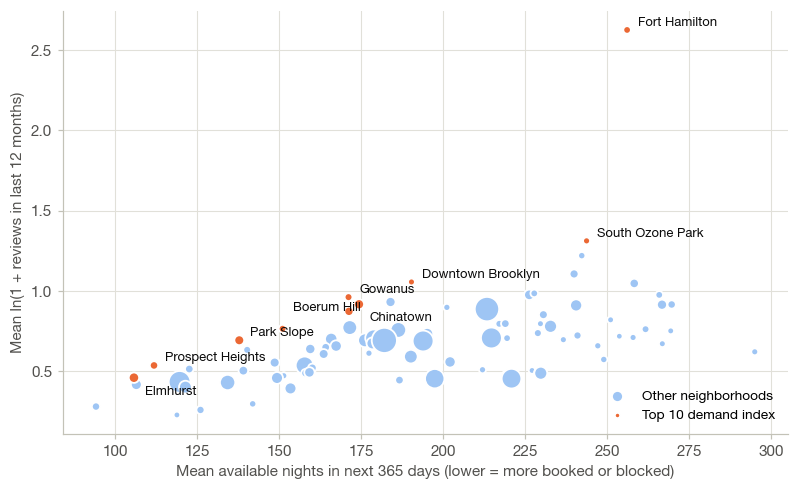

In [24]:
top = hood_pd.head(10)
rest = hood_pd.iloc[10:]
size = lambda n: 12 + n / hood_pd.listings.max() * 260
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(rest.mean_availability_365, rest.mean_log_reviews_ltm, s=size(rest.listings), color="#9ec5f4",
           edgecolors="white", linewidths=1.2, label="Other neighborhoods")
ax.scatter(top.mean_availability_365, top.mean_log_reviews_ltm, s=size(top.listings), color=SERIES[1],
           edgecolors="white", linewidths=1.2, label="Top 10 demand index")
fig.canvas.draw()  # fix axis limits so label extents are final
renderer = fig.canvas.get_renderer()
placed = []
for _, r in top.iterrows():
    # try a few offsets and keep the first that does not overlap an earlier label
    for dx, dy, ha in [(7, 3, "left"), (7, -11, "left"), (-7, 3, "right"), (-7, -11, "right"), (7, 12, "left")]:
        t = ax.annotate(r.neighbourhood, (r.mean_availability_365, r.mean_log_reviews_ltm), xytext=(dx, dy),
                        textcoords="offset points", fontsize=8.5, color=INK, ha=ha)
        bb = t.get_window_extent(renderer).expanded(1.05, 1.15)
        if not any(bb.overlaps(p) for p in placed):
            placed.append(bb)
            break
        t.remove()
ax.set(xlabel="Mean available nights in next 365 days (lower = more booked or blocked)",
       ylabel="Mean ln(1 + reviews in last 12 months)")
ax.legend(loc="lower right", markerscale=0.6)
save(fig, "fig7_neighbourhood_demand")

## 7. Wrap-up

In [25]:
print("Figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))
print("Tables :", sorted(p.name for p in OUT_DIR.glob("*.csv")))
spark.stop()

Figures: ['fig1_price_distribution.png', 'fig2_price_by_room_type.png', 'fig3_price_by_borough_room.png', 'fig4_price_map.png', 'fig5_minimum_stay.png', 'fig6_correlation.png', 'fig7_neighbourhood_demand.png']
Tables : ['correlation_matrix.csv', 'descriptive_numeric.csv', 'missing_values.csv', 'neighbourhood_demand.csv', 'price_by_borough.csv', 'price_by_is_superhost.csv', 'price_by_license_status.csv', 'price_by_room_type.csv', 'price_by_stay_type.csv', 'sample_flow.csv']
